# Visualizações e análise exploratória
Dados limpos de 10 vacas (T01 a T10) no dia 25/07/2023. Cada linha é uma janela de 10 s, com 16 atributos do acelerômetro do colar e o comportamento anotado.

Comportamentos (as 8 classes originais foram agrupadas em 3):
- **Deitada** (classe 7)
- **Em pé/andando** (classes 1 e 2)
- **Alimentação** (classes 4, 5 e 6: comer, lamber e beber)

Cada figura também é salva na pasta `figuras/`.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from pathlib import Path

# 1. Escolher o estilo dos gráficos e criar a pasta onde as figuras serão salvas
sns.set_theme(style="whitegrid")
Path("figuras").mkdir(exist_ok=True)

# 2. Definir o nome e a cor de cada comportamento (a mesma cor em todos os gráficos)
nomes = {7: "Deitada", 2: "Em pé/andando", 3: "Alimentação"}
ordem = ["Deitada", "Em pé/andando", "Alimentação"]
cores = {"Deitada": "#2a78d6", "Em pé/andando": "#eb6834", "Alimentação": "#1baf7a"}
lista_cores = [cores[nome] for nome in ordem]

# 3. Carregar e juntar os CSVs limpos de todas as vacas
files = sorted(Path("./dados/clean").glob("*.csv"))
df = pd.concat((pd.read_csv(f) for f in files), ignore_index=True)

# 4. Converter o comportamento para inteiro e criar a coluna com o nome dele
df["behavior"] = df["behavior"].astype(int)
df["comportamento"] = df["behavior"].map(nomes)

# 5. Converter o timestamp para a hora local do curral (CDT = UTC-5)
data_hora = pd.to_datetime(df["timestamp"], unit="s") - pd.Timedelta(hours=5)
df["hora"] = data_hora.dt.hour
df["hora_decimal"] = data_hora.dt.hour + data_hora.dt.minute / 60

print(f"{len(df)} janelas de 10 s | {df['vaca_id'].nunique()} vacas")

71244 janelas de 10 s | 10 vacas


## 1. Quanto tempo as vacas passam em cada comportamento?

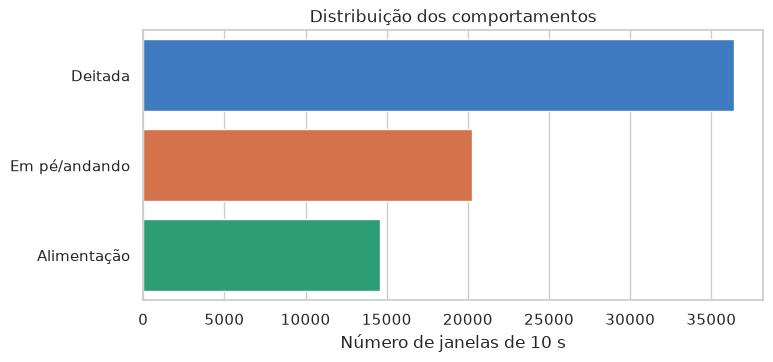

comportamento
Deitada          51.1
Em pé/andando    28.4
Alimentação      20.5
Name: proportion, dtype: float64


In [2]:
# 1. Contar as janelas de cada comportamento
plt.figure(figsize=(8, 3.5))
sns.countplot(
    data=df, y="comportamento", order=ordem, hue="comportamento", palette=cores, legend=False
)
plt.title("Distribuição dos comportamentos")
plt.xlabel("Número de janelas de 10 s")
plt.ylabel("")
plt.savefig("figuras/01_distribuicao_classes.png", dpi=150, bbox_inches="tight")
plt.show()

# 2. Calcular o percentual de cada comportamento
print((df["comportamento"].value_counts(normalize=True) * 100).round(1))

A classe **Deitada** ocupa pouco mais da metade dos dados. Um modelo que sempre responde "deitada" já acerta cerca de 51%. Esse é o chute inicial que o modelo precisa superar.

## 2. As vacas se comportam de forma parecida?

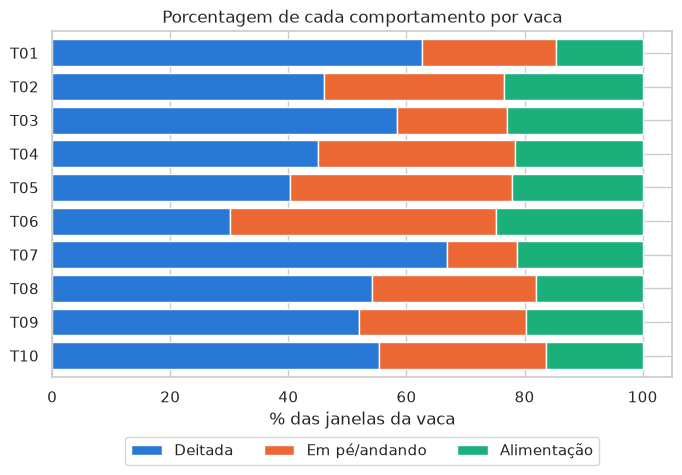

In [3]:
# 1. Calcular, para cada vaca, a porcentagem de tempo em cada comportamento
por_vaca = pd.crosstab(df["vaca_id"], df["comportamento"], normalize="index") * 100
por_vaca = por_vaca[ordem]

# 2. Plotar barras empilhadas (cada barra soma 100%)
por_vaca.plot(kind="barh", stacked=True, color=lista_cores, figsize=(8, 4.5), width=0.8)
plt.gca().invert_yaxis()
plt.title("Porcentagem de cada comportamento por vaca")
plt.xlabel("% das janelas da vaca")
plt.ylabel("")
plt.legend(ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.15))
plt.savefig("figuras/02_comportamento_por_vaca.png", dpi=150, bbox_inches="tight")
plt.show()

O padrão geral se repete, mas as proporções variam bastante entre as vacas (a T06 passa menos tempo deitada que a T07, por exemplo). Por isso o modelo precisa ser testado em vacas que ele não viu no treino.

## 3. O comportamento muda ao longo do dia?

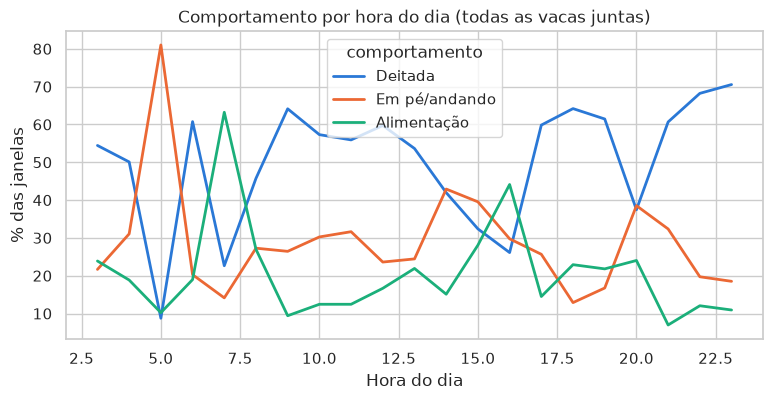

In [4]:
# 1. Calcular, para cada hora do dia, a porcentagem de cada comportamento
por_hora = pd.crosstab(df["hora"], df["comportamento"], normalize="index") * 100
por_hora = por_hora[ordem]

# 2. Remover a primeira hora, que tem poucas janelas (a coleta começa às 02:57)
por_hora = por_hora.iloc[1:]

# 3. Plotar uma linha para cada comportamento
por_hora.plot(kind="line", color=lista_cores, linewidth=2, figsize=(9, 4))
plt.title("Comportamento por hora do dia (todas as vacas juntas)")
plt.xlabel("Hora do dia")
plt.ylabel("% das janelas")
plt.savefig("figuras/03_comportamento_por_hora.png", dpi=150, bbox_inches="tight")
plt.show()

Cada ponto da linha diz: naquela hora, qual a porcentagem das janelas (de todas as vacas) em cada comportamento. A vaca passa mais tempo deitada à noite e no começo da tarde, e o pico de "em pé/andando" às 5h vem logo depois de um período sem dados (veja o gráfico 6).

## 4. Os atributos do sensor separam os comportamentos?

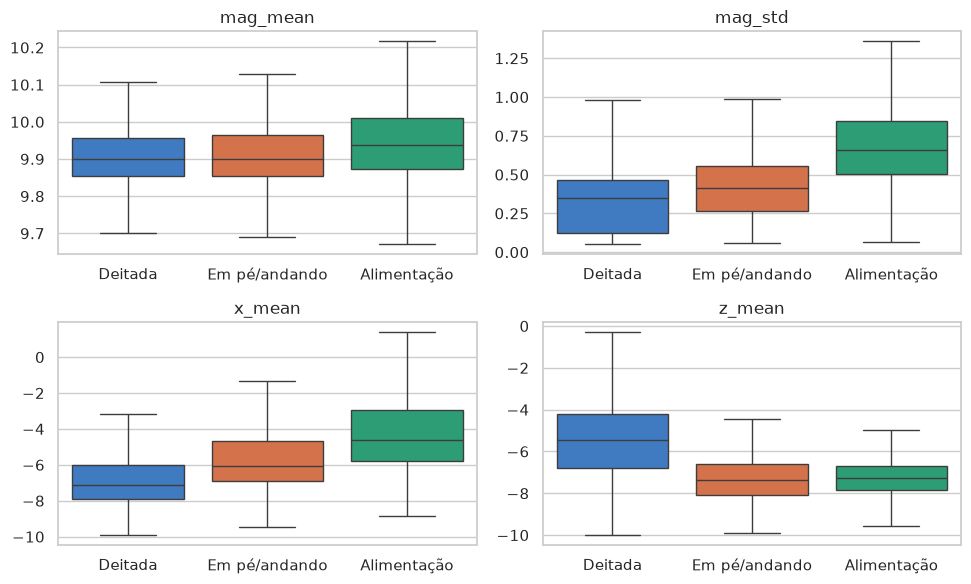

In [5]:
# 1. Escolher quatro atributos para comparar
atributos = ["mag_mean", "mag_std", "x_mean", "z_mean"]

# 2. Plotar um boxplot por atributo, separado por comportamento
fig, eixos = plt.subplots(2, 2, figsize=(10, 6))
for atributo, eixo in zip(atributos, eixos.flatten()):
    sns.boxplot(
        data=df, x="comportamento", y=atributo, order=ordem,
        hue="comportamento", palette=cores, legend=False, showfliers=False, ax=eixo,
    )
    eixo.set_title(atributo)
    eixo.set_xlabel("")
    eixo.set_ylabel("")
plt.tight_layout()
plt.savefig("figuras/04_atributos_por_classe.png", dpi=150, bbox_inches="tight")
plt.show()

Como ler um boxplot: a caixa mostra onde estão 50% dos valores e o traço do meio é a mediana.

**Nenhum atributo sozinho separa as três classes**: as caixas se sobrepõem bastante. As diferenças mais claras são:
- **Alimentação** tem o maior desvio padrão da magnitude (`mag_std`): a cabeça se mexe mais.
- **Deitada** tem a média de z (`z_mean`) menos negativa e mais dispersa.
- **Em pé/andando** fica no meio e se sobrepõe às outras classes.

Como cada atributo separa só parte dos casos, o modelo combina os 16 atributos. A sobreposição de "em pé/andando" com as outras antecipa onde ele vai errar mais.

## 5. Os atributos são redundantes entre si?

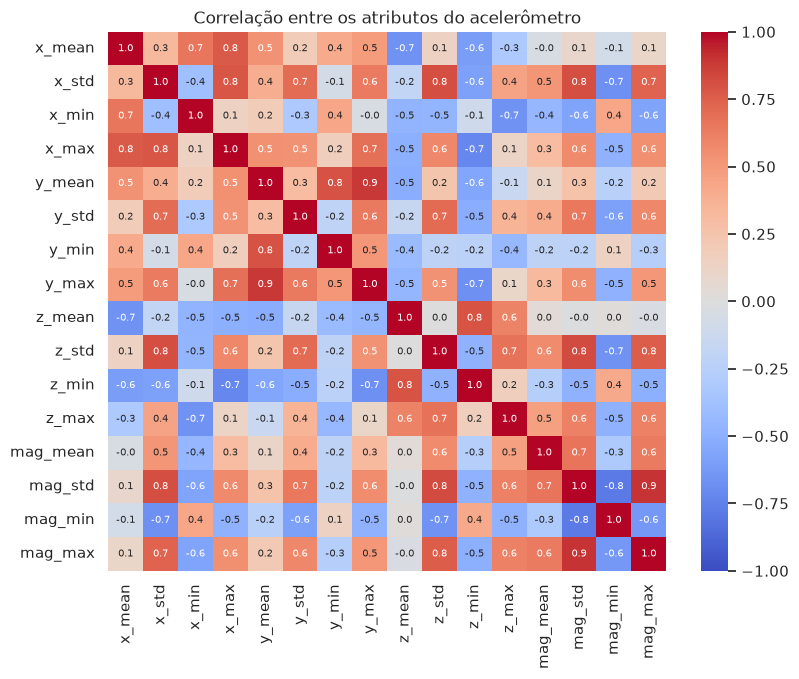

In [6]:
# 1. Calcular a correlação entre os 16 atributos
colunas_features = [c for c in df.columns if c.split("_")[0] in ("x", "y", "z", "mag")]
correlacao = df[colunas_features].corr()

# 2. Plotar o mapa de calor (vermelho = correlação positiva, azul = negativa)
plt.figure(figsize=(9, 7))
sns.heatmap(correlacao, cmap="coolwarm", center=0, vmin=-1, vmax=1, annot=True, fmt=".1f",
            annot_kws={"size": 7})
plt.title("Correlação entre os atributos do acelerômetro")
plt.savefig("figuras/05_correlacao_atributos.png", dpi=150, bbox_inches="tight")
plt.show()

Correlação perto de 1 (ou -1) significa que dois atributos dizem quase a mesma coisa. Dentro de cada eixo, média, mínimo e máximo têm correlação de 0,5 a 0,9 (por exemplo, `y_mean` com `y_max`: 0,9), e `mag_std` acompanha `mag_max` (0,9). Parte dos 16 atributos é redundante. Isso não atrapalha o Random Forest, mas seria o ponto de partida para reduzir atributos.

## 6. Linha do tempo de cada vaca

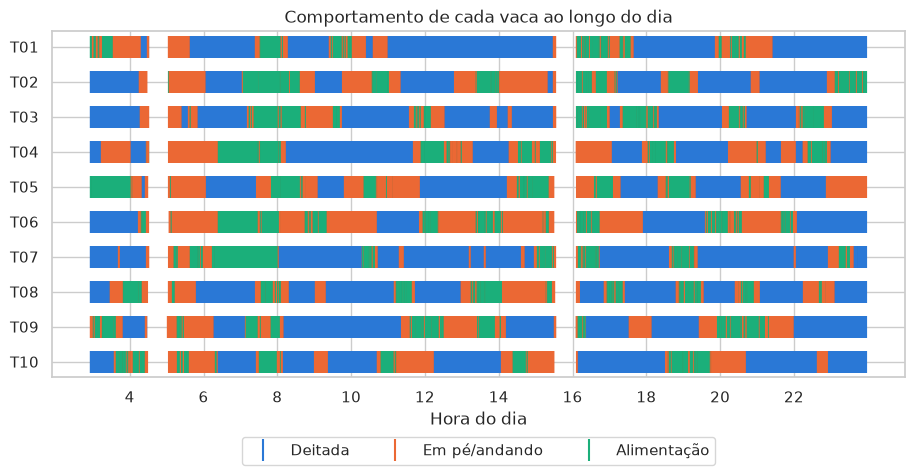

In [7]:
# 1. Plotar um traço vertical para cada janela de 10 s (linha = vaca, eixo x = hora)
plt.figure(figsize=(11, 4.5))
sns.scatterplot(
    data=df, x="hora_decimal", y="vaca_id", hue="comportamento", hue_order=ordem,
    palette=cores, marker="|", s=250, linewidth=1.5,
)
plt.xticks(range(4, 24, 2))
plt.title("Comportamento de cada vaca ao longo do dia")
plt.xlabel("Hora do dia")
plt.ylabel("")
plt.legend(ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.15))
plt.savefig("figuras/06_linha_do_tempo_vacas.png", dpi=150, bbox_inches="tight")
plt.show()

Como ler: **cada linha é uma vaca** e cada traço colorido é uma janela de 10 s. Para saber o que a T01 fazia às 10h, olhe a primeira linha na altura do 10 e veja a cor.

Dois pontos chamam atenção:
- Os comportamentos formam **blocos contínuos** de minutos a horas. Essa continuidade justifica usar as janelas vizinhas como contexto no notebook `melhorias.ipynb`.
- Há duas **lacunas em branco em todas as vacas ao mesmo tempo** (por volta de 4h30 a 5h e de 15h30 a 16h15), sem anotação válida. É provável que as vacas tenham saído do curral nesses horários, por exemplo para a ordenha, mas isso é hipótese e o README não confirma.